In [12]:
 import pandas as pd
import os

files = [f for f in os.listdir('/content') if f.endswith('.csv')]

print("Total CSV files:", len(files))

for file in files:
    df = pd.read_csv('/content/' + file)
    print(file, df.shape)

Total CSV files: 0


**Import Libraries**

In [13]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import plotly.express as px
import sqlite3
import os

print("All libraries imported successfully!")

All libraries imported successfully!


**DataLoader Class**

In [14]:
class DataLoader:

    def __init__(self, folder_path="/content"):
        self.folder_path = folder_path
        self.data = {}

    def load_data(self):

        for file in os.listdir(self.folder_path):

            if file.endswith(".csv"):

                path = os.path.join(self.folder_path, file)

                df = pd.read_csv(path)

                self.data[file] = df

                print(file, df.shape)

        return self.data

**Load All 9 Datasets**

In [15]:
loader = DataLoader()

data = loader.load_data()

print("Total datasets loaded:", len(data))

Total datasets loaded: 0


 **Check Dataset Information**

In [16]:
for name, df in data.items():

    print("\nDataset:", name)

    print("Shape:", df.shape)

    print("Missing Values:")
    print(df.isnull().sum())

    print("Data Types:")
    print(df.dtypes)

In [17]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [18]:

import os
import pandas as pd

class DataLoader:

    def __init__(self, folder_path="/content"):
        self.folder_path = folder_path
        self.data = {}

    def load_data(self):

        for file in os.listdir(self.folder_path):

            if file.endswith(".csv"):
                file_path = os.path.join(
                    self.folder_path, file
                )

                df = pd.read_csv(file_path)

                name = file.replace(".csv", "")
                self.data[name] = df

                print(name, df.shape)

        print("\nAll datasets loaded successfully!")


In [19]:
# Instantiate the DataLoader pointing to your Google Drive folder
loader = DataLoader(folder_path="/content/drive/MyDrive/Olist_Analysis")
loader.load_data()

print("\nTotal datasets loaded:", len(loader.data))


All datasets loaded successfully!

Total datasets loaded: 0


In [22]:
import os
import zipfile

base_path = "/content/drive/MyDrive/Olist_Analysis"
csv_folder = None

# 1. Search for CSV files or ZIP archives in Google Drive
for root, dirs, files in os.walk(base_path):
    if any(f.endswith('.csv') for f in files):
        csv_folder = root
        break

# 2. If no CSVs found, look for zip files to extract
if not csv_folder:
    for root, dirs, files in os.walk(base_path):
        zip_files = [f for f in files if f.endswith('.zip')]
        if zip_files:
            zip_path = os.path.join(root, zip_files[0])
            print(f"Found ZIP archive: {zip_path}. Extracting...")
            extract_to = "/content/olist_extracted"
            with zipfile.ZipFile(zip_path, 'r') as zip_ref:
                zip_ref.extractall(extract_to)
            csv_folder = extract_to
            break

# 3. Load the data using the discovered folder
if csv_folder:
    print(f"Loading CSV datasets from: {csv_folder}")
    loader = DataLoader(folder_path=csv_folder)
    loader.load_data()
    print("Total datasets successfully loaded:", len(loader.data))
else:
    print("Could not automatically locate CSV files or ZIP archives in your Google Drive folder.")

Loading CSV datasets from: /content/drive/MyDrive/Olist_Analysis/cleaned_data
olist_order_items_dataset (112650, 7)
olist_order_reviews_dataset (99224, 7)
olist_orders_dataset (99441, 8)
olist_geolocation_dataset (738332, 5)
olist_products_dataset (32951, 9)
olist_customers_dataset (99441, 5)
olist_sellers_dataset (3095, 4)
olist_order_payments_dataset (103886, 5)
product_category_name_translation (71, 2)

All datasets loaded successfully!
Total datasets successfully loaded: 9


In [47]:
# Display the first 5 rows of orders
orders = loader.data["olist_orders_dataset"]

display(orders.head())

# Check dataset information
orders.info()

# Check missing values
print(orders.isnull().sum())

,order_id,customer_id,order_status,order_purchase_timestamp,order_approved_at,order_delivered_carrier_date,order_delivered_customer_date,order_estimated_delivery_date
0,e481f51cbdc54678b7cc49136f2d6af7,9ef432eb6251297304e76186b10a928d,delivered,2017-10-02 10:56:33,2017-10-02 11:07:15,2017-10-04 19:55:00,2017-10-10 21:25:13,2017-10-18
1,53cdb2fc8bc7dce0b6741e2150273451,b0830fb4747a6c6d20dea0b8c802d7ef,delivered,2018-07-24 20:41:37,2018-07-26 03:24:27,2018-07-26 14:31:00,2018-08-07 15:27:45,2018-08-13
2,47770eb9100c2d0c44946d9cf07ec65d,41ce2a54c0b03bf3443c3d931a367089,delivered,2018-08-08 08:38:49,2018-08-08 08:55:23,2018-08-08 13:50:00,2018-08-17 18:06:29,2018-09-04
3,949d5b44dbf5de918fe9c16f97b45f8a,f88197465ea7920adcdbec7375364d82,delivered,2017-11-18 19:28:06,2017-11-18 19:45:59,2017-11-22 13:39:59,2017-12-02 00:28:42,2017-12-15
4,ad21c59c0840e6cb83a9ceb5573f8159,8ab97904e6daea8866dbdbc4fb7aad2c,delivered,2018-02-13 21:18:39,2018-02-13 22:20:29,2018-02-14 19:46:34,2018-02-16 18:17:02,2018-02-26


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 99441 entries, 0 to 99440
Data columns (total 8 columns):
 #   Column                         Non-Null Count  Dtype 
---  ------                         --------------  ----- 
 0   order_id                       99441 non-null  object
 1   customer_id                    99441 non-null  object
 2   order_status                   99441 non-null  object
 3   order_purchase_timestamp       99441 non-null  object
 4   order_approved_at              99281 non-null  object
 5   order_delivered_carrier_date   97658 non-null  object
 6   order_delivered_customer_date  96476 non-null  object
 7   order_estimated_delivery_date  99441 non-null  object
dtypes: object(8)
memory usage: 6.1+ MB
order_id                            0
customer_id                         0
order_status                        0
order_purchase_timestamp            0
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2

In [24]:

# Check all loaded datasets

print("Total datasets:", len(loader.data))

for name, df in loader.data.items():

    print("\nDataset:", name)
    print("Rows and Columns:", df.shape)
    print("Missing Values:", df.isnull().sum().sum())
    print("Duplicate Rows:", df.duplicated().sum())


Total datasets: 9

Dataset: olist_order_items_dataset
Rows and Columns: (112650, 7)
Missing Values: 0
Duplicate Rows: 0

Dataset: olist_order_reviews_dataset
Rows and Columns: (99224, 7)
Missing Values: 145903
Duplicate Rows: 0

Dataset: olist_orders_dataset
Rows and Columns: (99441, 8)
Missing Values: 4908
Duplicate Rows: 0

Dataset: olist_geolocation_dataset
Rows and Columns: (738332, 5)
Missing Values: 0
Duplicate Rows: 0

Dataset: olist_products_dataset
Rows and Columns: (32951, 9)
Missing Values: 1838
Duplicate Rows: 0

Dataset: olist_customers_dataset
Rows and Columns: (99441, 5)
Missing Values: 0
Duplicate Rows: 0

Dataset: olist_sellers_dataset
Rows and Columns: (3095, 4)
Missing Values: 0
Duplicate Rows: 0

Dataset: olist_order_payments_dataset
Rows and Columns: (103886, 5)
Missing Values: 0
Duplicate Rows: 0

Dataset: product_category_name_translation
Rows and Columns: (71, 2)
Missing Values: 0
Duplicate Rows: 0


**Remove duplicate records**

In [25]:

# Create copies so original data remains unchanged

cleaned_data = {}

for name, df in loader.data.items():

    df_clean = df.copy()

    before = len(df_clean)

    df_clean = df_clean.drop_duplicates()

    after = len(df_clean)

    cleaned_data[name] = df_clean

    print(name)
    print("Duplicates removed:", before - after)


olist_order_items_dataset
Duplicates removed: 0
olist_order_reviews_dataset
Duplicates removed: 0
olist_orders_dataset
Duplicates removed: 0
olist_geolocation_dataset
Duplicates removed: 0
olist_products_dataset
Duplicates removed: 0
olist_customers_dataset
Duplicates removed: 0
olist_sellers_dataset
Duplicates removed: 0
olist_order_payments_dataset
Duplicates removed: 0
product_category_name_translation
Duplicates removed: 0


**Convert date columns into datetime**

In [26]:

# Convert date columns

for name, df in cleaned_data.items():

    for col in df.columns:

        if "date" in col.lower():
            df[col] = pd.to_datetime(
                df[col],
                errors="coerce"
            )

    print("\nConverted:", name)

print("\nDate conversion completed!")



Converted: olist_order_items_dataset

Converted: olist_order_reviews_dataset

Converted: olist_orders_dataset

Converted: olist_geolocation_dataset

Converted: olist_products_dataset

Converted: olist_customers_dataset

Converted: olist_sellers_dataset

Converted: olist_order_payments_dataset

Converted: product_category_name_translation

Date conversion completed!


**Clean missing values**

In [27]:

for name, df in cleaned_data.items():

    print("\nDataset:", name)

    missing = df.isnull().sum()

    print(missing[missing > 0])



Dataset: olist_order_items_dataset
Series([], dtype: int64)

Dataset: olist_order_reviews_dataset
review_comment_title      87656
review_comment_message    58247
dtype: int64

Dataset: olist_orders_dataset
order_approved_at                 160
order_delivered_carrier_date     1783
order_delivered_customer_date    2965
dtype: int64

Dataset: olist_geolocation_dataset
Series([], dtype: int64)

Dataset: olist_products_dataset
product_name_lenght           610
product_description_lenght    610
product_photos_qty            610
product_weight_g                2
product_length_cm               2
product_height_cm               2
product_width_cm                2
dtype: int64

Dataset: olist_customers_dataset
Series([], dtype: int64)

Dataset: olist_sellers_dataset
Series([], dtype: int64)

Dataset: olist_order_payments_dataset
Series([], dtype: int64)

Dataset: product_category_name_translation
Series([], dtype: int64)


In [28]:

# Fill missing product categories

products = cleaned_data["olist_products_dataset"]

products["product_category_name"] = (
    products["product_category_name"]
    .fillna("Unknown")
)

print("Missing product categories:",
      products["product_category_name"].isnull().sum())


Missing product categories: 0


**Check data consistency**

In [29]:

# Correct datetime conversion

for name, df in cleaned_data.items():

    for col in df.columns:

        if "date" in col.lower() or "timestamp" in col.lower():

            df[col] = pd.to_datetime(
                df[col],
                errors="coerce"
            )

print("All date and timestamp columns checked!")


All date and timestamp columns checked!


In [30]:

# Check orders

orders = cleaned_data["olist_orders_dataset"]

print("Order status:")
print(orders["order_status"].value_counts())

# Check product prices

items = cleaned_data["olist_order_items_dataset"]

print("\nNegative product prices:")
print((items["price"] < 0).sum())

print("\nNegative freight values:")
print((items["freight_value"] < 0).sum())


Order status:
order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64

Negative product prices:
0

Negative freight values:
0


**Save all cleaned datasets**

In [31]:

import os

# Create a folder for cleaned data

output_folder = "/content/cleaned_data"

os.makedirs(output_folder, exist_ok=True)

# Save all cleaned datasets

for name, df in cleaned_data.items():

    file_path = os.path.join(
        output_folder,
        name + ".csv"
    )

    df.to_csv(file_path, index=False)

    print("Saved:", name)

print("\nAll cleaned datasets saved successfully!")


Saved: olist_order_items_dataset
Saved: olist_order_reviews_dataset
Saved: olist_orders_dataset
Saved: olist_geolocation_dataset
Saved: olist_products_dataset
Saved: olist_customers_dataset
Saved: olist_sellers_dataset
Saved: olist_order_payments_dataset
Saved: product_category_name_translation

All cleaned datasets saved successfully!


**Final verification**

In [32]:

# Final cleaning report

for name, df in cleaned_data.items():

    print("\nDataset:", name)
    print("Shape:", df.shape)
    print("Duplicates:", df.duplicated().sum())
    print("Missing values:", df.isnull().sum().sum())

print("\nSTEP 9 PROCESS FINISHED!")



Dataset: olist_order_items_dataset
Shape: (112650, 7)
Duplicates: 0
Missing values: 0

Dataset: olist_order_reviews_dataset
Shape: (99224, 7)
Duplicates: 0
Missing values: 145903

Dataset: olist_orders_dataset
Shape: (99441, 8)
Duplicates: 0
Missing values: 4908

Dataset: olist_geolocation_dataset
Shape: (738332, 5)
Duplicates: 0
Missing values: 0

Dataset: olist_products_dataset
Shape: (32951, 9)
Duplicates: 0
Missing values: 1838

Dataset: olist_customers_dataset
Shape: (99441, 5)
Duplicates: 0
Missing values: 0

Dataset: olist_sellers_dataset
Shape: (3095, 4)
Duplicates: 0
Missing values: 0

Dataset: olist_order_payments_dataset
Shape: (103886, 5)
Duplicates: 0
Missing values: 0

Dataset: product_category_name_translation
Shape: (71, 2)
Duplicates: 0
Missing values: 0

STEP 9 PROCESS FINISHED!


In [33]:
# Prepare Delivered Sales Dataset

# Select only delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
].copy()

# Merge delivered orders with order items
delivered_sales = pd.merge(
    delivered_orders[
        ["order_id", "customer_id", "order_purchase_timestamp"]
    ],
    items,
    on="order_id",
    how="inner"
)

# Calculate total product revenue
total_revenue = delivered_sales["price"].sum()

print("DELIVERED SALES DATASET CREATED")
print("Total Delivered Orders:",
      delivered_sales["order_id"].nunique())

print("Total Sales Records:", len(delivered_sales))

print("Total Product Revenue: R$",
      round(total_revenue, 2))

DELIVERED SALES DATASET CREATED
Total Delivered Orders: 96478
Total Sales Records: 110197
Total Product Revenue: R$ 13221498.11


In [34]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
import os

# Load cleaned datasets

folder = "/content/cleaned_data"

data = {}

for file in os.listdir(folder):

    if file.endswith(".csv"):

        name = file.replace(".csv", "")

        data[name] = pd.read_csv(
            os.path.join(folder, file)
        )

print("Total datasets:", len(data))
print("All cleaned datasets loaded!")


Total datasets: 9
All cleaned datasets loaded!


In [35]:

orders = data["olist_orders_dataset"]

items = data["olist_order_items_dataset"]

customers = data["olist_customers_dataset"]

products = data["olist_products_dataset"]

payments = data["olist_order_payments_dataset"]

print("All required datasets are ready!")


All required datasets are ready!


**Order analysis**

order_status
delivered      96478
shipped         1107
canceled         625
unavailable      609
invoiced         314
processing       301
created            5
approved           2
Name: count, dtype: int64


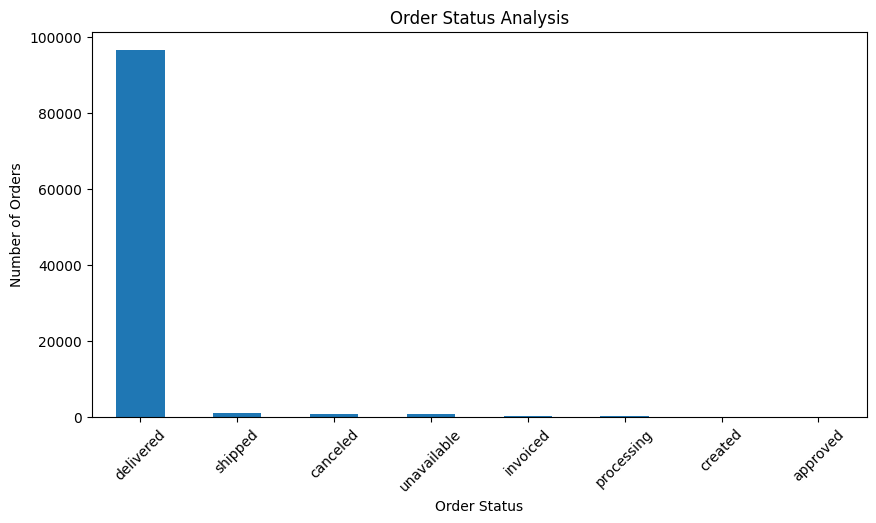

In [36]:

# Order status analysis

print(orders["order_status"].value_counts())

# Count each order status
status_count = orders["order_status"].value_counts()

# Create bar chart
plt.figure(figsize=(10, 5))

status_count.plot(kind="bar")

plt.title("Order Status Analysis")
plt.xlabel("Order Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=45)

plt.show()


**Sales and revenue analysis**

TOP 10 PRODUCT CATEGORIES BY REVENUE


,price
product_category_name,
beleza_saude,1233131.72
relogios_presentes,1166176.98
cama_mesa_banho,1023434.76
esporte_lazer,954852.55
informatica_acessorios,888724.61
moveis_decoracao,711927.69
utilidades_domesticas,615628.69
cool_stuff,610204.10
automotivo,578966.65


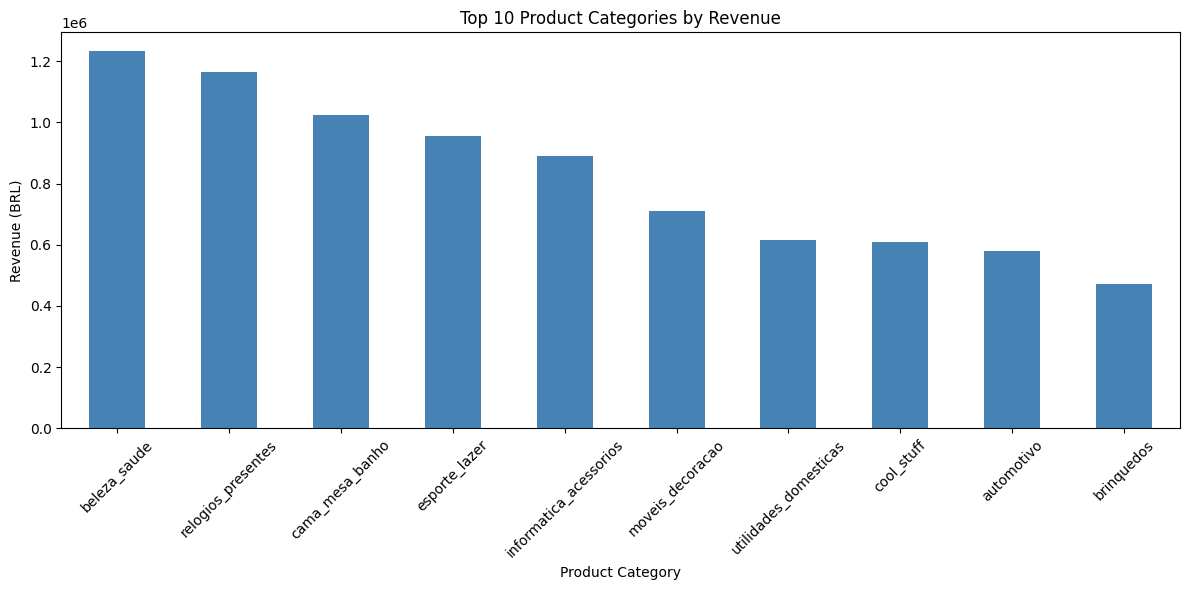

In [37]:

# STEP 10.1 - Product Revenue Analysis

# Merge delivered sales with product information

product_sales = pd.merge(
    delivered_sales,
    products,
    on="product_id",
    how="left"
)

# Calculate revenue by product category

category_revenue = (
    product_sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 categories

print("TOP 10 PRODUCT CATEGORIES BY REVENUE")

display(category_revenue.head(10))

# Create visualization

plt.figure(figsize=(12, 6))

category_revenue.head(10).plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Monthly sales analysis**

month
2016-09       134.97
2016-10     40325.11
2016-12        10.90
2017-01    111798.36
2017-02    234223.40
2017-03    359198.85
2017-04    340669.68
2017-05    489338.25
2017-06    421923.37
2017-07    481604.52
2017-08    554699.70
2017-09    607399.67
2017-10    648247.65
2017-11    987765.37
2017-12    726033.19
2018-01    924645.00
2018-02    826437.13
2018-03    953356.25
2018-04    973534.09
2018-05    977544.69
2018-06    856077.86
2018-07    867953.46
2018-08    838576.64
Name: price, dtype: float64


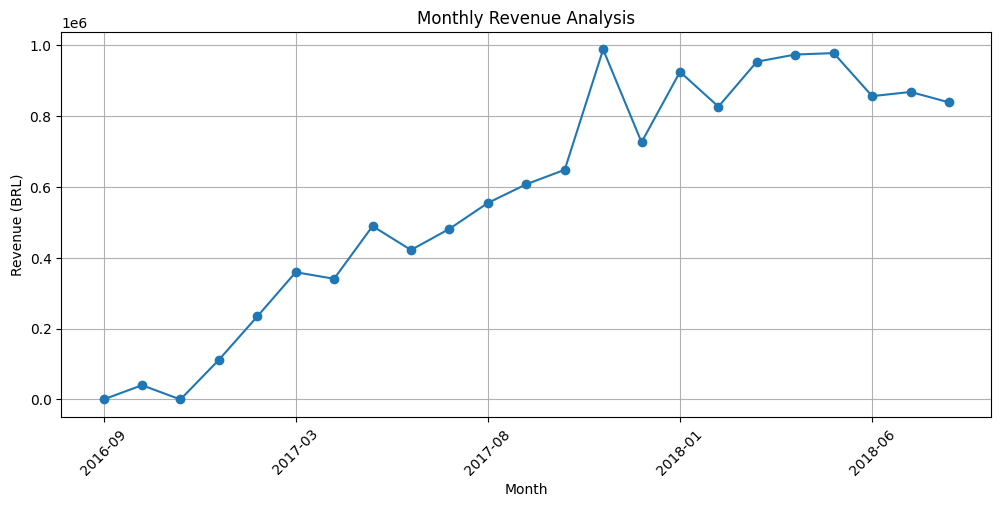

In [38]:

# Convert purchase timestamp

delivered_sales["order_purchase_timestamp"] = pd.to_datetime(
    delivered_sales["order_purchase_timestamp"],
    errors="coerce"
)

# Extract month

delivered_sales["month"] = (
    delivered_sales["order_purchase_timestamp"]
    .dt.to_period("M")
    .astype(str)
)

# Monthly revenue

monthly_sales = (
    delivered_sales.groupby("month")["price"]
    .sum()
)

print(monthly_sales)

# Visualization

plt.figure(figsize=(12, 5))

monthly_sales.plot(kind="line", marker="o")

plt.title("Monthly Revenue Analysis")
plt.xlabel("Month")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)

plt.grid()
plt.show()


**Product analysis**

In [39]:

# Merge items with products

product_sales = pd.merge(
    items,
    products,
    on="product_id",
    how="left"
)

# Revenue by product category

category_revenue = (
    product_sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

print("Top 10 Product Categories:")

print(category_revenue.head(10))


Top 10 Product Categories:
product_category_name
beleza_saude              1258681.34
relogios_presentes        1205005.68
cama_mesa_banho           1036988.68
esporte_lazer              988048.97
informatica_acessorios     911954.32
moveis_decoracao           729762.49
cool_stuff                 635290.85
utilidades_domesticas      632248.66
automotivo                 592720.11
ferramentas_jardim         485256.46
Name: price, dtype: float64


**Create a chart**

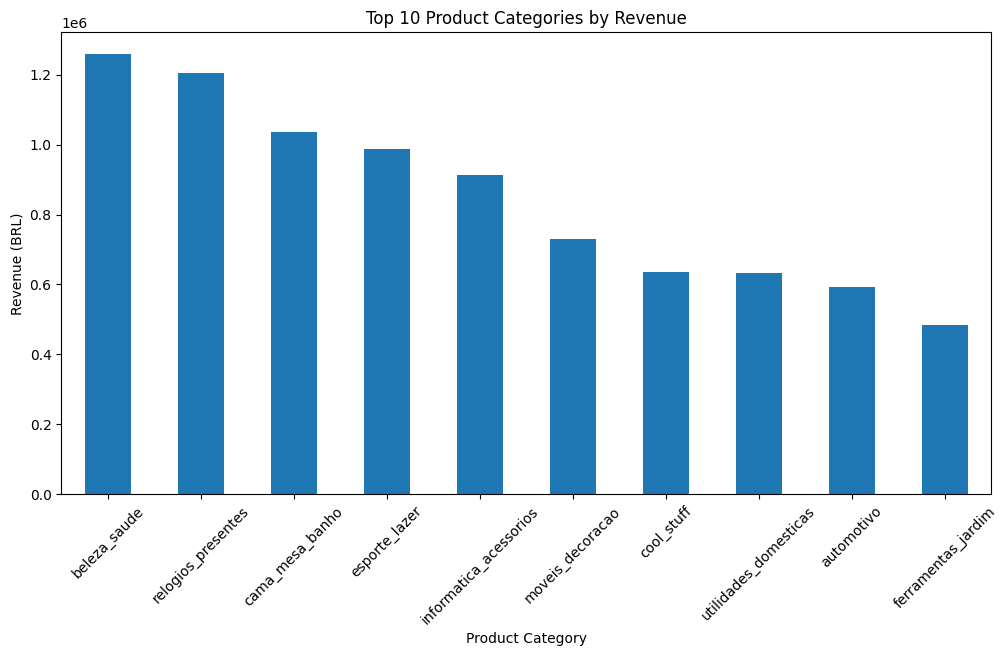

In [40]:

plt.figure(figsize=(12, 6))

category_revenue.head(10).plot(kind="bar")

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue (BRL)")

plt.xticks(rotation=45)
plt.show()


**Customer analysis**

TOP 10 STATES BY UNIQUE CUSTOMERS


,customer_unique_id
customer_state,
SP,40302
RJ,12384
MG,11259
RS,5277
PR,4882
SC,3534
BA,3277
DF,2075
ES,1964


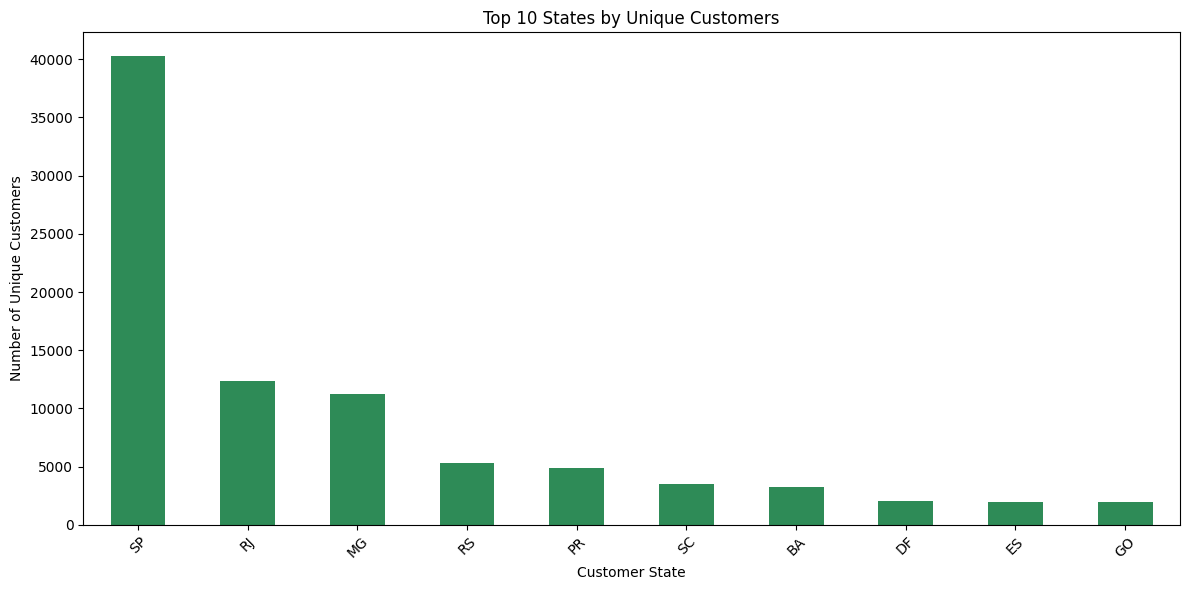

Total Unique Customers: 96096


In [41]:

# STEP 10.2 - Unique Customer Analysis

# Count unique customers by state

state_customers = (
    customers.groupby("customer_state")
    ["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("TOP 10 STATES BY UNIQUE CUSTOMERS")

display(state_customers.head(10))

# Create visualization

plt.figure(figsize=(12, 6))

state_customers.head(10).plot(
    kind="bar",
    color="seagreen"
)

plt.title("Top 10 States by Unique Customers")
plt.xlabel("Customer State")
plt.ylabel("Number of Unique Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# Total unique customers

print(
    "Total Unique Customers:",
    customers["customer_unique_id"].nunique()
)


**Bonus: Payment method analysis**

PAYMENT PERFORMANCE REPORT


,Total_Payments,Unique_Orders,Total_Payment_Value,Average_Payment_Value
payment_type,,,,
credit_card,76795,76505,12542084.19,163.32
boleto,19784,19784,2869361.27,145.03
voucher,5775,3866,379436.87,65.70
debit_card,1529,1528,217989.79,142.57
not_defined,3,3,0.00,0.00


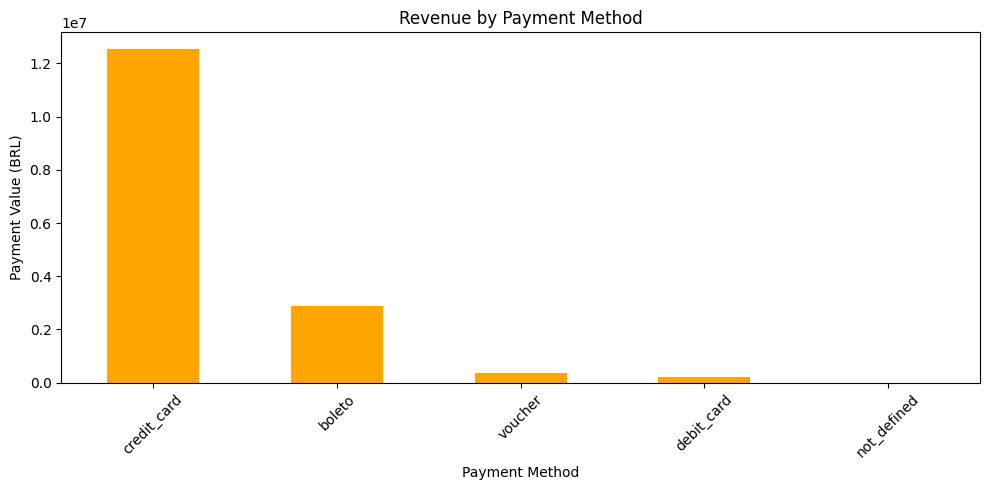

In [42]:

# STEP 10.3 - Payment Performance Analysis

payment_summary = (
    payments.groupby("payment_type")
    .agg(
        Total_Payments=("payment_type", "count"),
        Unique_Orders=("order_id", "nunique"),
        Total_Payment_Value=("payment_value", "sum"),
        Average_Payment_Value=("payment_value", "mean")
    )
    .sort_values(
        by="Total_Payment_Value",
        ascending=False
    )
)

print("PAYMENT PERFORMANCE REPORT")

display(payment_summary.round(2))

# Payment value visualization

plt.figure(figsize=(10, 5))

payment_summary["Total_Payment_Value"].plot(
    kind="bar",
    color="orange"
)

plt.title("Revenue by Payment Method")
plt.xlabel("Payment Method")
plt.ylabel("Payment Value (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


**Delivery performance analysis**

In [43]:

# STEP 10.4 - Advanced Delivery Analysis

# Convert delivery date columns

date_columns = [
    "order_purchase_timestamp",
    "order_delivered_customer_date",
    "order_estimated_delivery_date"
]

for col in date_columns:
    orders[col] = pd.to_datetime(
        orders[col],
        errors="coerce"
    )

# Select delivered orders with valid dates

delivery = orders[
    (orders["order_status"] == "delivered") &
    (orders["order_purchase_timestamp"].notna()) &
    (orders["order_delivered_customer_date"].notna()) &
    (orders["order_estimated_delivery_date"].notna())
].copy()

# Calculate actual delivery days

delivery["delivery_days"] = (
    delivery["order_delivered_customer_date"] -
    delivery["order_purchase_timestamp"]
).dt.total_seconds() / 86400

# Calculate estimated delivery performance

delivery["delivery_status"] = np.where(
    delivery["order_delivered_customer_date"] <=
    delivery["order_estimated_delivery_date"],
    "On Time",
    "Late"
)

# Remove invalid negative delivery durations

delivery = delivery[
    delivery["delivery_days"] >= 0
].copy()

# Display report

print("DELIVERY PERFORMANCE REPORT")

print("Total Delivered Orders:", len(delivery))

print(
    "Average Delivery Days:",
    round(delivery["delivery_days"].mean(), 2)
)

print(
    "Median Delivery Days:",
    round(delivery["delivery_days"].median(), 2)
)

print("\nDelivery Status:")

display(
    delivery["delivery_status"].value_counts()
)

# Calculate delivery percentages

delivery_percentage = (
    delivery["delivery_status"]
    .value_counts(normalize=True) * 100
)

print("\nDelivery Percentage:")

display(delivery_percentage.round(2))


DELIVERY PERFORMANCE REPORT
Total Delivered Orders: 96470
Average Delivery Days: 12.56
Median Delivery Days: 10.22

Delivery Status:


,count
delivery_status,
On Time,88644
Late,7826



Delivery Percentage:


,proportion
delivery_status,
On Time,91.89
Late,8.11


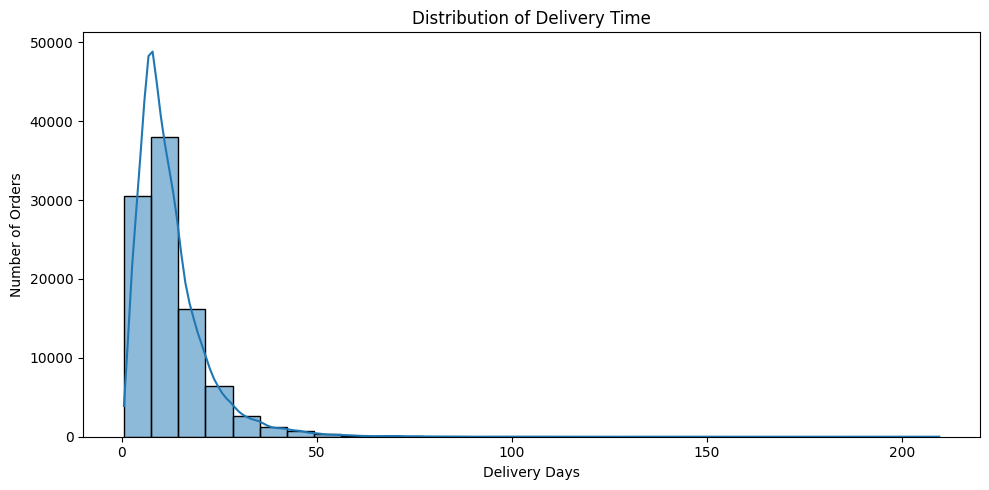

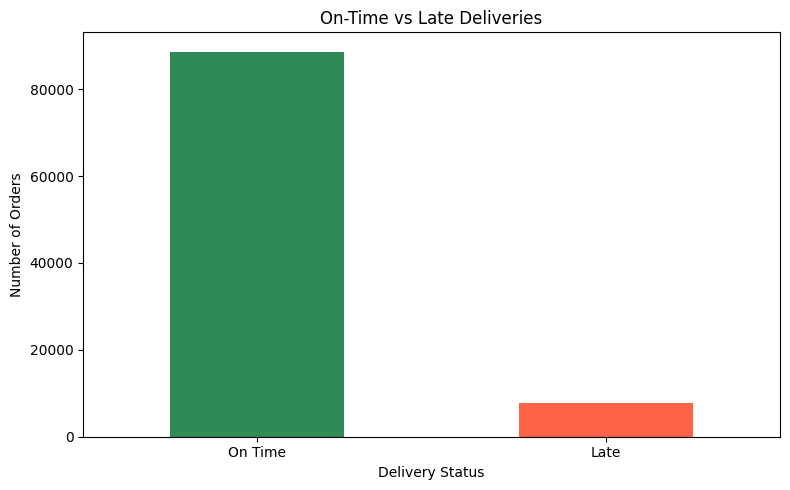

In [44]:

# Delivery Time Distribution

plt.figure(figsize=(10, 5))

sns.histplot(
    data=delivery,
    x="delivery_days",
    bins=30,
    kde=True
)

plt.title("Distribution of Delivery Time")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")
plt.tight_layout()
plt.show()

# On-time vs late deliveries

plt.figure(figsize=(8, 5))

delivery["delivery_status"].value_counts().plot(
    kind="bar",
    color=["seagreen", "tomato"]
)

plt.title("On-Time vs Late Deliveries")
plt.xlabel("Delivery Status")
plt.ylabel("Number of Orders")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()


**Delivery visualization**

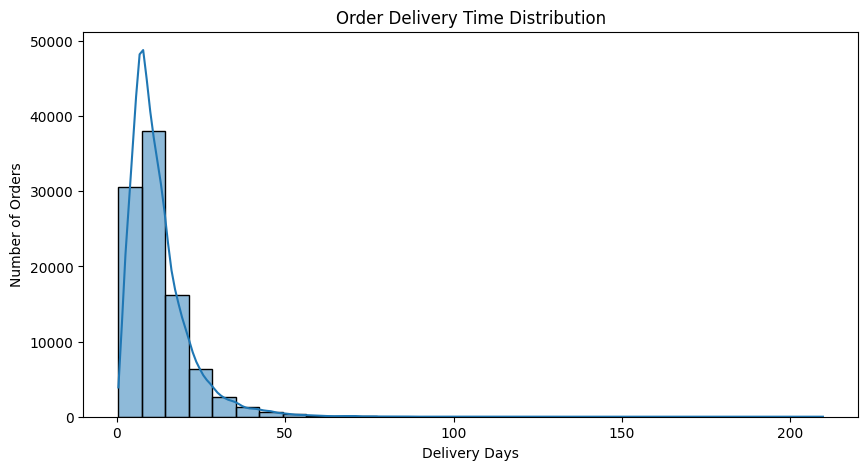

In [45]:

plt.figure(figsize=(10, 5))

sns.histplot(
    delivery["delivery_days"],
    bins=30,
    kde=True
)

plt.title("Order Delivery Time Distribution")
plt.xlabel("Delivery Days")
plt.ylabel("Number of Orders")

plt.show()


In [48]:
print("TOTAL REVENUE:", total_revenue)

print("\nMOST POPULAR PAYMENT:")
print(payment_summary["Total_Payments"].idxmax())

print("\nTOP CUSTOMER STATE:")
print(state_customers.idxmax())

print("\nAVERAGE DELIVERY DAYS:")
print(round(delivery["delivery_days"].mean(), 2))

TOTAL REVENUE: 13221498.110000001

MOST POPULAR PAYMENT:
credit_card

TOP CUSTOMER STATE:
SP

AVERAGE DELIVERY DAYS:
12.56


In [49]:

# Detailed Missing Value Report

for name, df in cleaned_data.items():

    missing = df.isnull().sum()

    report = pd.DataFrame({
        "Missing_Count": missing,
        "Missing_Percentage": (
            missing / len(df) * 100
        ).round(2)
    })

    report = report[report["Missing_Count"] > 0]

    if not report.empty:
        print("\nDataset:", name)
        display(report)



Dataset: olist_order_reviews_dataset


,Missing_Count,Missing_Percentage
review_comment_title,87656,88.34
review_comment_message,58247,58.70



Dataset: olist_orders_dataset


,Missing_Count,Missing_Percentage
order_approved_at,160,0.16
order_delivered_carrier_date,1783,1.79
order_delivered_customer_date,2965,2.98



Dataset: olist_products_dataset


,Missing_Count,Missing_Percentage
product_name_lenght,610,1.85
product_description_lenght,610,1.85
product_photos_qty,610,1.85
product_weight_g,2,0.01
product_length_cm,2,0.01
product_height_cm,2,0.01
product_width_cm,2,0.01


Top 10 States by Unique Customers:


,customer_unique_id
customer_state,
SP,40302
RJ,12384
MG,11259
RS,5277
PR,4882
SC,3534
BA,3277
DF,2075
ES,1964


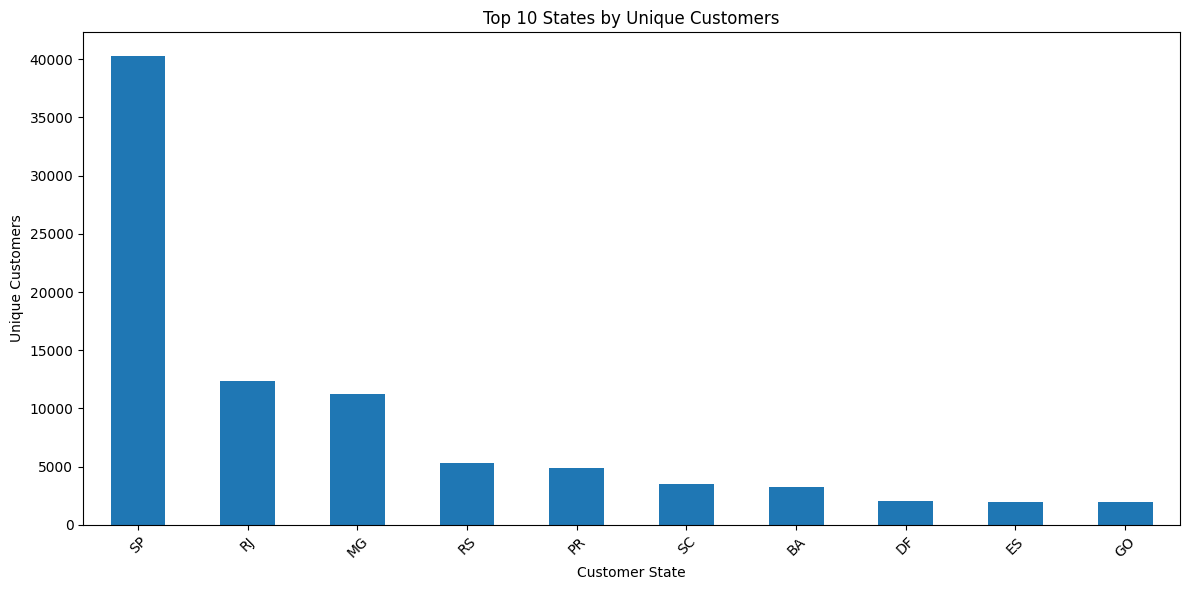

In [50]:

# Unique customer analysis by state

state_customers = (
    customers.groupby("customer_state")
    ["customer_unique_id"]
    .nunique()
    .sort_values(ascending=False)
)

print("Top 10 States by Unique Customers:")
display(state_customers.head(10))

plt.figure(figsize=(12, 6))

state_customers.head(10).plot(kind="bar")

plt.title("Top 10 States by Unique Customers")
plt.xlabel("Customer State")
plt.ylabel("Unique Customers")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


TOP 10 PRODUCT CATEGORIES BY REVENUE


,price
product_category_name,
beleza_saude,1233131.72
relogios_presentes,1166176.98
cama_mesa_banho,1023434.76
esporte_lazer,954852.55
informatica_acessorios,888724.61
moveis_decoracao,711927.69
utilidades_domesticas,615628.69
cool_stuff,610204.10
automotivo,578966.65


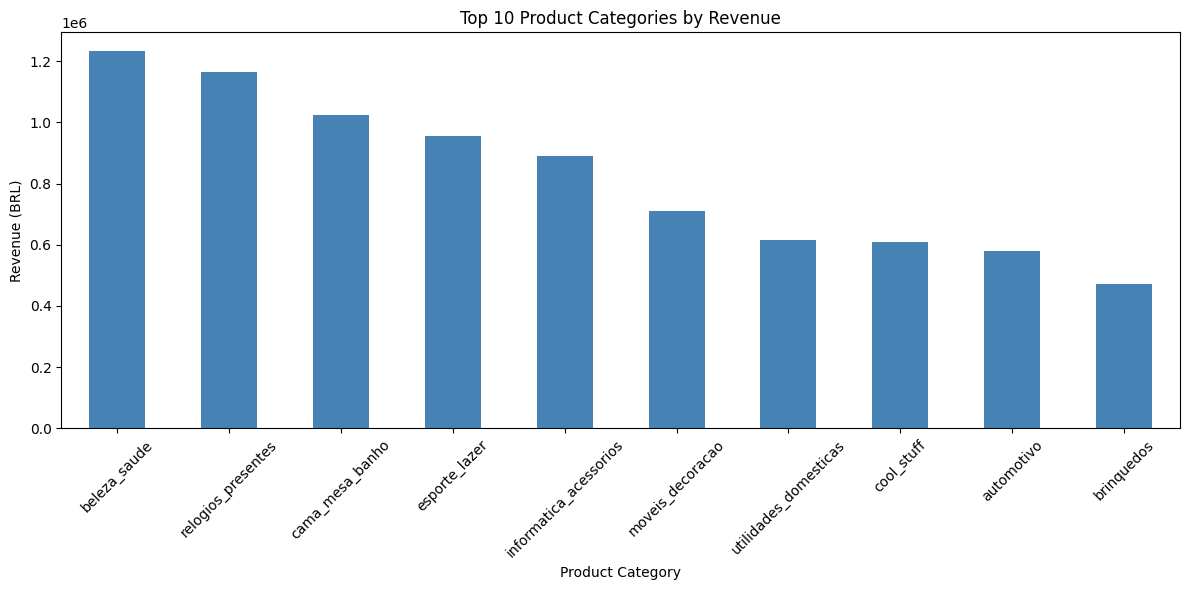

In [51]:

# STEP 10.1 - Product Revenue Analysis

# Merge delivered sales with product information

product_sales = pd.merge(
    delivered_sales,
    products,
    on="product_id",
    how="left"
)

# Calculate revenue by product category

category_revenue = (
    product_sales.groupby("product_category_name")["price"]
    .sum()
    .sort_values(ascending=False)
)

# Display top 10 categories

print("TOP 10 PRODUCT CATEGORIES BY REVENUE")

display(category_revenue.head(10))

# Create visualization

plt.figure(figsize=(12, 6))

category_revenue.head(10).plot(
    kind="bar",
    color="steelblue"
)

plt.title("Top 10 Product Categories by Revenue")
plt.xlabel("Product Category")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()


In [52]:
output_folder = (
    "/content/drive/MyDrive/"
    "Olist_Analysis/cleaned_data"
)

os.makedirs(output_folder, exist_ok=True)

for name, df in cleaned_data.items():

    df.to_csv(
        os.path.join(output_folder, name + ".csv"),
        index=False
    )

print("All datasets saved to Google Drive!")

All datasets saved to Google Drive!


**business summary**

In [53]:

# STEP 10.5 - FINAL BUSINESS INSIGHTS

print("=" * 50)
print("OLIST E-COMMERCE BUSINESS INSIGHTS")
print("=" * 50)

# 1. Total Revenue

print("\n1. TOTAL REVENUE")

print(
    "R$",
    round(delivered_sales["price"].sum(), 2)
)

# 2. Delivered Orders

print("\n2. DELIVERED ORDERS")

print(
    delivered_sales["order_id"].nunique()
)

# 3. Top Product Category

print("\n3. TOP PRODUCT CATEGORY")

print(category_revenue.idxmax())

# 4. Top Customer State

print("\n4. TOP CUSTOMER STATE")

print(state_customers.idxmax())

# 5. Most Popular Payment Method

print("\n5. MOST USED PAYMENT METHOD")

print(payment_summary["Total_Payments"].idxmax())

# 6. Average Delivery Time

print("\n6. AVERAGE DELIVERY TIME")

print(
    round(delivery["delivery_days"].mean(), 2),
    "days"
)

# 7. On-Time Delivery Percentage

print("\n7. ON-TIME DELIVERY PERCENTAGE")

print(
    round(
        delivery_percentage.get("On Time", 0),
        2
    ),
    "%"
)

print("\n" + "=" * 50)
print("BUSINESS INSIGHTS REPORT COMPLETED")
print("=" * 50)


OLIST E-COMMERCE BUSINESS INSIGHTS

1. TOTAL REVENUE
R$ 13221498.11

2. DELIVERED ORDERS
96478

3. TOP PRODUCT CATEGORY
beleza_saude

4. TOP CUSTOMER STATE
SP

5. MOST USED PAYMENT METHOD
credit_card

6. AVERAGE DELIVERY TIME
12.56 days

7. ON-TIME DELIVERY PERCENTAGE
91.89 %

BUSINESS INSIGHTS REPORT COMPLETED


## **CUSTOMER RETENTION & REPEAT PURCHASE ANALYSIS**

Objectives:
1. Identify unique customers.
2. Find one-time customers.
3. Find repeat customers.
4. Calculate the repeat customer percentage.
5. Visualize customer purchasing behavior.

**customer analysis code**

In [54]:
# STEP 11.1 - Customer Retention Analysis

# Select delivered orders
delivered_orders = orders[
    orders["order_status"] == "delivered"
][["order_id", "customer_id"]].copy()

# Connect orders with unique customer information
customer_orders = pd.merge(
    delivered_orders,
    customers[["customer_id", "customer_unique_id"]],
    on="customer_id",
    how="left"
)

# Count delivered orders made by each unique customer
customer_frequency = (
    customer_orders
    .dropna(subset=["customer_unique_id"])
    .groupby("customer_unique_id")["order_id"]
    .nunique()
)

# Separate one-time and repeat customers
one_time_customers = (customer_frequency == 1).sum()
repeat_customers = (customer_frequency >= 2).sum()

total_customers = len(customer_frequency)

# Calculate repeat customer percentage
repeat_percentage = (
    repeat_customers / total_customers * 100
    if total_customers > 0 else 0
)

# Display results
print("CUSTOMER RETENTION REPORT")
print("-" * 40)

print("Total Unique Customers:", total_customers)
print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

print(
    "Repeat Customer Percentage:",
    round(repeat_percentage, 2), "%"
)

CUSTOMER RETENTION REPORT
----------------------------------------
Total Unique Customers: 93358
One-Time Customers: 90557
Repeat Customers: 2801
Repeat Customer Percentage: 3.0 %


**visualization**

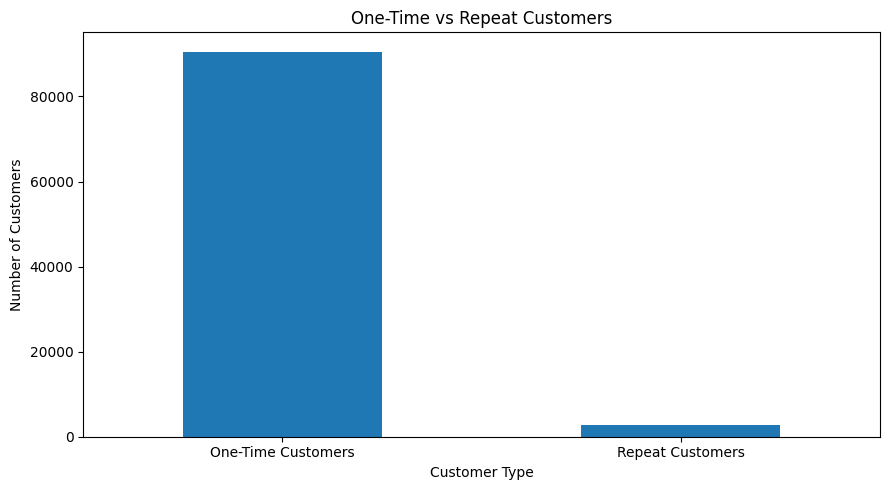

In [55]:
# STEP 11.2 - Customer Purchase Behavior Chart

customer_types = pd.Series({
    "One-Time Customers": one_time_customers,
    "Repeat Customers": repeat_customers
})

plt.figure(figsize=(9, 5))

customer_types.plot(kind="bar")

plt.title("One-Time vs Repeat Customers")
plt.xlabel("Customer Type")
plt.ylabel("Number of Customers")
plt.xticks(rotation=0)

plt.tight_layout()
plt.show()

**business insights**

In [56]:
# STEP 11.3 - Customer Retention Insights

print("CUSTOMER BUSINESS INSIGHTS")
print("-" * 40)

print(
    f"{repeat_percentage:.2f}% of unique customers "
    "made more than one delivered purchase."
)

if repeat_percentage < 20:
    print("Business Insight: Repeat purchasing is relatively low.")
else:
    print("Business Insight: Some customers are returning to purchase again.")

print("One-Time Customers:", one_time_customers)
print("Repeat Customers:", repeat_customers)

CUSTOMER BUSINESS INSIGHTS
----------------------------------------
3.00% of unique customers made more than one delivered purchase.
Business Insight: Repeat purchasing is relatively low.
One-Time Customers: 90557
Repeat Customers: 2801


# STEP 12: SELLER PERFORMANCE ANALYSIS

Objectives:
1. Calculate total sales per seller.
2. Count orders per seller.
3. Identify the top 10 sellers.
4. Visualize seller performance.

In [57]:
# STEP 12.1 - Seller Performance Analysis

# Create delivered sales data
delivered_orders = orders[
    orders["order_status"] == "delivered"
]

delivered_sales = pd.merge(
    delivered_orders[["order_id"]],
    items,
    on="order_id",
    how="inner"
)

# Add seller information
seller_sales = pd.merge(
    delivered_sales,
    data["olist_sellers_dataset"],
    on="seller_id",
    how="left"
)

# Calculate seller performance
seller_performance = (
    seller_sales.groupby("seller_id")
    .agg(
        Total_Orders=("order_id", "nunique"),
        Total_Items=("order_item_id", "count"),
        Total_Revenue=("price", "sum"),
        Seller_State=("seller_state", "first")
    )
    .sort_values("Total_Revenue", ascending=False)
)

print("TOP 10 SELLERS BY REVENUE")

display(seller_performance.head(10).round(2))

TOP 10 SELLERS BY REVENUE


,Total_Orders,Total_Items,Total_Revenue,Seller_State
seller_id,,,,
4869f7a5dfa277a7dca6462dcf3b52b2,1124,1148,226987.93,SP
53243585a1d6dc2643021fd1853d8905,348,400,217940.44,BA
4a3ca9315b744ce9f8e9374361493884,1772,1949,196882.12,SP
fa1c13f2614d7b5c4749cbc52fecda94,578,579,190917.14,SP
7c67e1448b00f6e969d365cea6b010ab,973,1355,186570.05,SP
7e93a43ef30c4f03f38b393420bc753a,319,322,165981.49,SP
da8622b14eb17ae2831f4ac5b9dab84a,1311,1548,159816.87,SP
7a67c85e85bb2ce8582c35f2203ad736,1145,1155,139658.69,SP
1025f0e2d44d7041d6cf58b6550e0bfa,910,1420,138208.56,SP


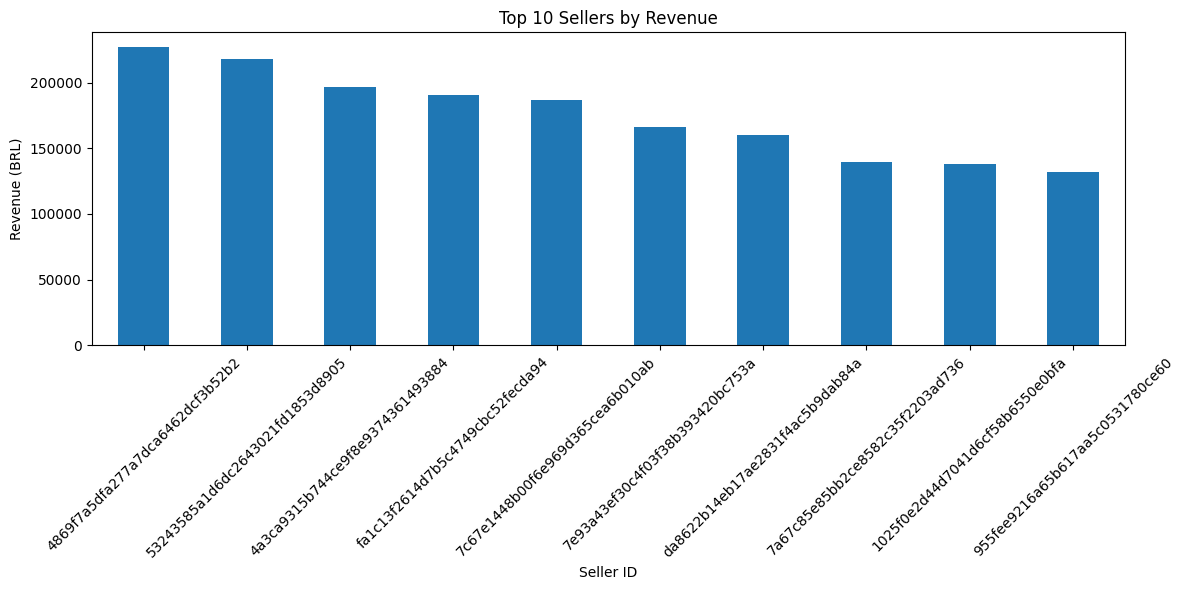

In [58]:
# STEP 12.2 - Top 10 Sellers Chart

top_sellers = seller_performance.head(10)

plt.figure(figsize=(12, 6))

top_sellers["Total_Revenue"].plot(kind="bar")

plt.title("Top 10 Sellers by Revenue")
plt.xlabel("Seller ID")
plt.ylabel("Revenue (BRL)")
plt.xticks(rotation=45)
plt.tight_layout()
plt.show()

# STEP 13: CUSTOMER REVIEW & SATISFACTION ANALYSIS

Objectives:
1. Analyze customer review scores.
2. Calculate average review score.
3. Identify positive, neutral and negative reviews.
4. Visualize customer satisfaction.

In [59]:
# STEP 13.1 - Customer Review Analysis

reviews = data["olist_order_reviews_dataset"]

# Calculate average review score
average_score = reviews["review_score"].mean()

print("CUSTOMER SATISFACTION REPORT")
print("-" * 40)

print("Total Reviews:", len(reviews))
print("Average Review Score:", round(average_score, 2))

# Count review scores
review_counts = reviews["review_score"].value_counts().sort_index()

display(review_counts)

CUSTOMER SATISFACTION REPORT
----------------------------------------
Total Reviews: 99224
Average Review Score: 4.09


,count
review_score,
1,11424
2,3151
3,8179
4,19142
5,57328


In [60]:
# STEP 13.2 - Satisfaction Categories

reviews["satisfaction"] = reviews["review_score"].apply(
    lambda score:
    "Positive" if score >= 4
    else "Neutral" if score == 3
    else "Negative"
)

satisfaction_counts = reviews["satisfaction"].value_counts()

display(satisfaction_counts)

satisfaction_percentage = (
    satisfaction_counts / len(reviews) * 100
)

display(satisfaction_percentage.round(2))

,count
satisfaction,
Positive,76470
Negative,14575
Neutral,8179


,count
satisfaction,
Positive,77.07
Negative,14.69
Neutral,8.24


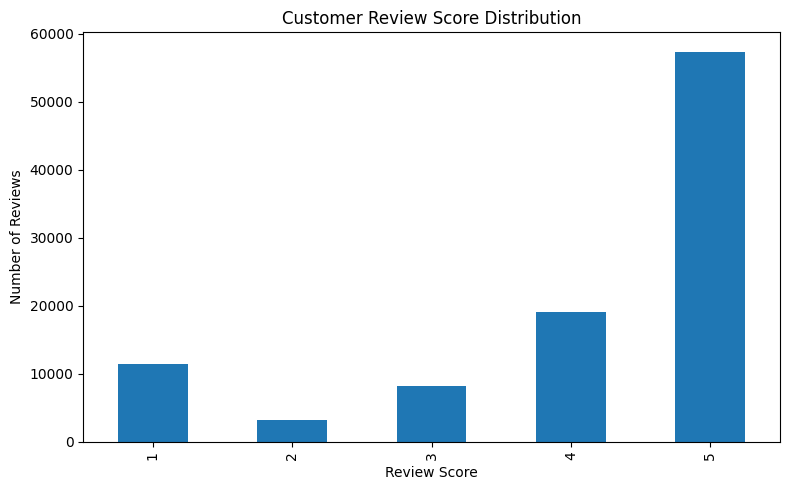

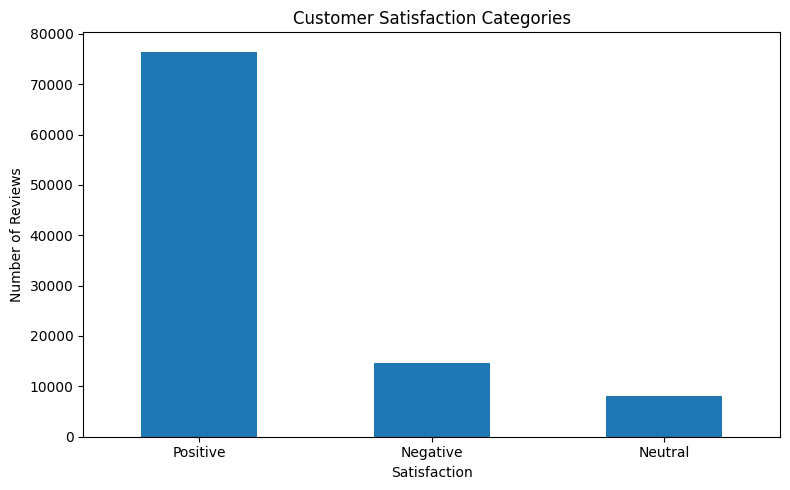

In [61]:
# STEP 13.3 - Customer Satisfaction Visualization

plt.figure(figsize=(8, 5))

review_counts.plot(kind="bar")

plt.title("Customer Review Score Distribution")
plt.xlabel("Review Score")
plt.ylabel("Number of Reviews")
plt.tight_layout()
plt.show()

plt.figure(figsize=(8, 5))

satisfaction_counts.plot(kind="bar")

plt.title("Customer Satisfaction Categories")
plt.xlabel("Satisfaction")
plt.ylabel("Number of Reviews")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

# STEP 14: FINAL BUSINESS INSIGHTS & RECOMMENDATIONS

Objectives:
1. Summarize sales performance.
2. Identify top product categories and sellers.
3. Understand customer retention.
4. Evaluate delivery performance.
5. Analyze customer satisfaction.
6. Provide business recommendations.

In [62]:
# STEP 14.1 - OLIST FINAL BUSINESS REPORT

print("=" * 55)
print("       OLIST E-COMMERCE BUSINESS REPORT")
print("=" * 55)

print("\n1. SALES PERFORMANCE")
print("Delivered Revenue: R$", round(delivered_sales["price"].sum(), 2))
print("Delivered Orders:", delivered_sales["order_id"].nunique())

print("\n2. PRODUCT PERFORMANCE")
print("Top Product Category:", category_revenue.idxmax())

print("\n3. SELLER PERFORMANCE")
print("Top Seller:", seller_performance.index[0])

print("\n4. CUSTOMER RETENTION")
print("Repeat Customers:", repeat_customers)
print("Repeat Customer Percentage:", round(repeat_percentage, 2), "%")

print("\n5. CUSTOMER SATISFACTION")
print("Average Review Score:", round(average_score, 2), "/ 5")

print("\n6. DELIVERY PERFORMANCE")
print("Average Delivery Days:", round(delivery["delivery_days"].mean(), 2))
print("On-Time Delivery:", round(delivery_percentage.get("On Time", 0), 2), "%")

print("\n" + "=" * 55)
print("           END OF BUSINESS REPORT")
print("=" * 55)

       OLIST E-COMMERCE BUSINESS REPORT

1. SALES PERFORMANCE
Delivered Revenue: R$ 13221498.11
Delivered Orders: 96478

2. PRODUCT PERFORMANCE
Top Product Category: beleza_saude

3. SELLER PERFORMANCE
Top Seller: 4869f7a5dfa277a7dca6462dcf3b52b2

4. CUSTOMER RETENTION
Repeat Customers: 2801
Repeat Customer Percentage: 3.0 %

5. CUSTOMER SATISFACTION
Average Review Score: 4.09 / 5

6. DELIVERY PERFORMANCE
Average Delivery Days: 12.56
On-Time Delivery: 91.89 %

           END OF BUSINESS REPORT


**BUSINESS RECOMMENDATIONS**

1. **Customer Retention**:
   Introduce loyalty programs to encourage repeat purchases.

2. **Seller Performance**:
   Support low-performing sellers and learn from top-performing sellers.

3. **Delivery Performance**:
   Improve logistics and reduce late deliveries.

4. **Customer Satisfaction**:
   Investigate negative reviews and improve product and service quality.

5. **Sales Growth**:
   Focus on high-performing product categories.

### Exporting Business Insights to CSV
We will compile the key business metrics (sales, product categories, delivery times, satisfaction scores, and customer retention) into a structured CSV file for export.

In [66]:
import pandas as pd
from google.colab import files

# Compile the business insights into a dictionary
insights_data = {
    "Metric": [
        "Total Delivered Revenue (BRL)",
        "Total Delivered Orders",
        "Top Product Category",
        "Top Customer State",
        "Most Used Payment Method",
        "Average Delivery Days",
        "On-Time Delivery Percentage",
        "Repeat Customers Count",
        "Repeat Customer Percentage",
        "Average Customer Review Score"
    ],
    "Value": [
        round(delivered_sales["price"].sum(), 2),
        int(delivered_sales["order_id"].nunique()),
        str(category_revenue.idxmax()),
        str(state_customers.idxmax()),
        str(payment_summary["Total_Payments"].idxmax()),
        round(delivery["delivery_days"].mean(), 2),
        f"{round(delivery_percentage.get('On Time', 0), 2)}%",
        int(repeat_customers),
        f"{round(repeat_percentage, 2)}%",
        f"{round(average_score, 2)} / 5"
    ]
}

# Create a DataFrame
insights_df = pd.DataFrame(insights_data)

# Save to a CSV file
csv_path = "/content/olist_business_insights.csv"
insights_df.to_csv(csv_path, index=False)

print(f"Business insights successfully compiled and saved to: {csv_path}")
display(insights_df)

# Trigger browser download of the CSV
files.download(csv_path)

Business insights successfully compiled and saved to: /content/olist_business_insights.csv


,Metric,Value
0,Total Delivered Revenue (BRL),13221498.11
1,Total Delivered Orders,96478
2,Top Product Category,beleza_saude
3,Top Customer State,SP
4,Most Used Payment Method,credit_card
5,Average Delivery Days,12.56
6,On-Time Delivery Percentage,91.89%
7,Repeat Customers Count,2801
8,Repeat Customer Percentage,3.0%
9,Average Customer Review Score,4.09 / 5


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>